##### Universidad Torcuato Di Tella

#### Tecnología Digital VI: Inteligencia Artificial

# **TP N°3: Redes Neuronales Convolucionales (CNNs)**

### Ariel Alzogaray Flores, Lucas Rehmann, Josefina Deserti Gotta

En primer lugar, importamos todos los paquetes necesarios para la realización del trabajo práctico.

In [22]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torchvision

from torch.utils.data import DataLoader, Subset
import torchvision.transforms as transforms

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
# Nos fijamos si vamos a usar GPU o CPU
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')


In [3]:
# Fijamos la semilla 
torch.manual_seed(100)
if torch.cuda.is_available():
    torch.cuda.manual_seed(100)

In [30]:
# Borrador del primer modelo
modelo = nn.Sequential(
    # Primera capa convolucional
    nn.Conv2d(in_channels = 3,   # 1 canal de entrada.
              out_channels = 32, # 32 canales de salida.
              kernel_size = 3,   # Kernel 3x3.
              stride = 1,        # Pasos de 1.
              padding = 1),       # Padding de 1 para mantener el tamaño.
    nn.LeakyReLU(),
    nn.MaxPool2d(kernel_size = 2, stride = 2),

    # Segunda capa convolucional
    nn.Conv2d(in_channels = 32, out_channels = 64, kernel_size = 3, stride = 1, padding = 1),
    nn.LeakyReLU(),
    nn.MaxPool2d(kernel_size = 2, stride = 2),

    nn.Flatten(),

    # Capa fully-conected
    nn.Linear(32 * 16 * 16, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)

In [31]:
criterio = nn.BCELoss()

# Datos

Cargamos el dataset. Torchvision ya nos da una implementación para descargar y cargar la versión RGB del dataset EuroSAT.

In [32]:
dataset = torchvision.datasets.EuroSAT(
    root="./data",
    download=True,
)

clases = dataset.classes
num_clases = len(clases)

print("Clases:", clases)
print("Cantidad de clases:", num_clases)
print("Cantidad de imágenes:", len(dataset))

Clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Cantidad de clases: 10
Cantidad de imágenes: 27000


Separamos en entrenamiento, validación y test.

In [33]:
indices = np.arange(len(dataset))
etiquetas = dataset.targets

idx_train, idx_temp = train_test_split(
    indices,
    test_size=0.30,
    stratify=etiquetas,
    random_state=100
)

idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    stratify=np.array(etiquetas)[idx_temp],
    random_state=100
)

Definimos transformaciones para Data Augmentation.

En estas imagenes la clase no esta necesariamente determinada por la orientación, por lo que aplicar reflejos y rotaciones es pertinente. Sin embargo, esto no lo vamos a realizar sobre los conjuntos de validación y test para poder evaluar el modelo sobre datos que representen su distribución original.

Las imagenes originales cargadas a tensores se encuentran en un rango de $[0,1]$, por lo que aplicamos una normalización que centra los valores en un rango de $[-1,1]$ con media y desviación estandar iguales a 0.5. Asi logramos que los gradientes de la red se propaguen de forma mas equilibrada, mantenemos consistencia en las entradas, y coherencia con los conjuntos de validación y test.

In [23]:
# Para entrenamiento
transform_train = torchvision.transforms.Compose([
    transforms.RandomHorizontalFlip(), # reflejo horizontal
    transforms.RandomVerticalFlip(), # reflejo vertical
    transforms.RandomChoice([ # rotacion aleatoria
        transforms.RandomRotation((0, 0)),
        transforms.RandomRotation((90, 90)),
        transforms.RandomRotation((180, 180)),
        transforms.RandomRotation((270, 270))
    ]),
    transforms.ToTensor(), # conversion a tensor
    transforms.Normalize( # normalizacion de valores
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

# Para validación y test
transform_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

Aplicamos las transformaciones.

In [24]:
dataset_train = torchvision.datasets.EuroSAT(
    root="./data",
    transform=transform_train
)

dataset_eval = torchvision.datasets.EuroSAT(
    root="./data",
    transform=transform_eval
)

train_data = Subset(dataset_train, idx_train)
val_data = Subset(dataset_eval, idx_val)
test_data = Subset(dataset_eval, idx_test)

Creamos los DataLoaders.

In [25]:
batch_size = 64

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

Verificamos dimensiones de tensores.

In [28]:
# Obtenemos un batch de entrenamiento
imagenes, etiquetas = next(iter(train_loader))

print("Dimensiones de las imágenes:", imagenes.shape)
print("Dimensiones de las etiquetas:", etiquetas.shape)
print("Etiquetas del batch:", etiquetas)

print("Cantidad de clases:", num_clases)

Dimensiones de las imágenes: torch.Size([64, 3, 64, 64])
Dimensiones de las etiquetas: torch.Size([64])
Etiquetas del batch: tensor([9, 8, 2, 6, 2, 4, 8, 6, 1, 3, 6, 0, 9, 7, 0, 0, 0, 3, 4, 4, 2, 6, 0, 4,
        5, 9, 7, 3, 8, 7, 0, 3, 1, 1, 1, 1, 0, 4, 4, 3, 3, 0, 4, 3, 6, 1, 0, 2,
        1, 2, 1, 4, 2, 7, 0, 6, 2, 0, 1, 9, 4, 4, 9, 7])
Cantidad de clases: 10


Por ultimo visualizamos algunas imagenes.

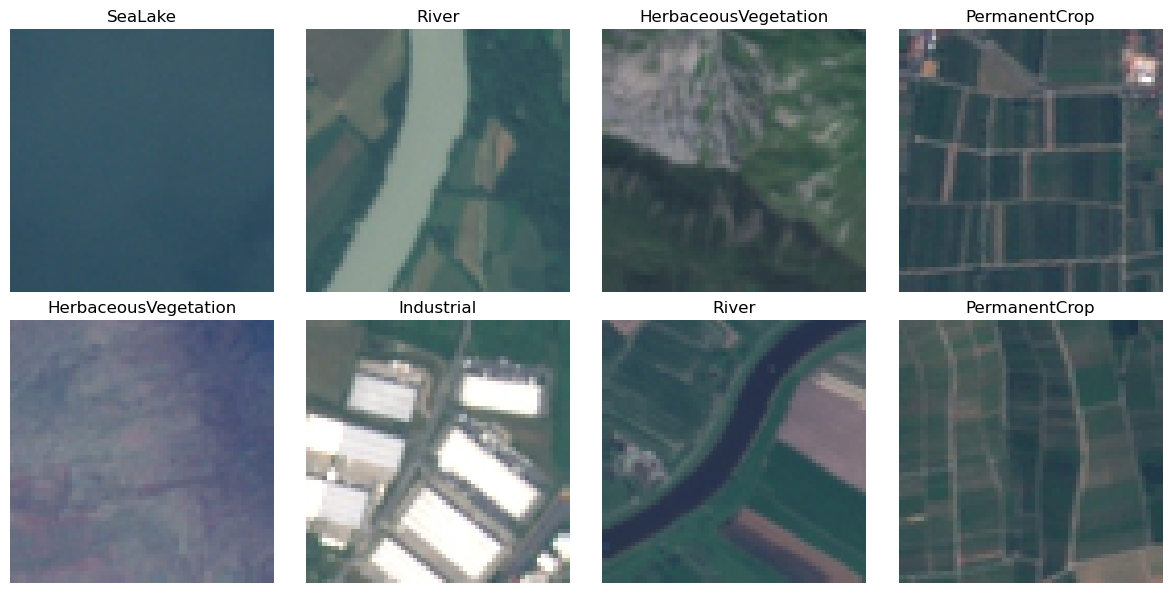

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = imagenes[i].permute(1, 2, 0)

    # Desnormalizamos para visualizar
    img = img * 0.5 + 0.5

    ax.imshow(img)
    ax.set_title(clases[etiquetas[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()